# Reflective AI Chart Generator

An agentic AI workflow that generates data visualisations from a CSV dataset and improves them through reflection.

The workflow follows four steps:

1. **Generate:** An OpenAI model writes Python code to create a chart.
2. **Execute:** Python runs the generated code and saves the chart.
3. **Reflect:** A vision-capable model evaluates the chart and suggests improvements.
4. **Refine:** The system generates and executes improved code.

**Technologies:** Python, OpenAI API, Pandas and Matplotlib.

*Inspired by the DeepLearning.AI Agentic AI course — rewritten and extended as an independent learning project.*

## 1. Setup

Import the libraries required for data processing, visualisation and interaction with the OpenAI API.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from openai import OpenAI

# Load API credentials
load_dotenv(".env")

# Initialise OpenAI client
client = OpenAI()

## 2. Load and Explore the Dataset

The project uses a coffee sales dataset to demonstrate AI-assisted data visualisation.

Pandas loads the CSV file into a DataFrame, allowing us to inspect the dataset before generating charts.

Our objective is to compare total coffee sales during the first quarter (Q1) of 2024 and 2025.

The LLM will use the dataset's column names and data types to generate Python code for this comparison.

In [2]:
# Load the dataset
df = pd.read_csv("coffee_sales.csv")

# Preview the data
display(df.head())

,date,time,cash_type,card,price,coffee_name
0,2024-03-01,06:14,card,ANON-0000-0000-0001,3.87,Latte
1,2024-03-01,11:10,card,ANON-0000-0000-0002,3.87,Hot Chocolate
2,2024-03-01,11:19,card,ANON-0000-0000-0002,3.87,Hot Chocolate
3,2024-03-01,11:37,card,ANON-0000-0000-0003,2.89,Americano
4,2024-03-01,12:56,card,ANON-0000-0000-0004,3.87,Latte


## 3. Generate Chart Code Using an LLM

In this stage, an OpenAI model translates a natural-language instruction into Python code for data visualisation.

The model receives:

- **User instruction:** A description of the required chart.
- **Dataset schema:** Column names and data types.
- **Generation requirements:** Instructions for creating and saving the chart.

The model generates Python code using Pandas and Matplotlib.

This demonstrates **LLM-based code generation**, which forms the first stage of our agentic workflow.

The generated code is reviewed before execution to reduce the risk of errors or unsafe operations.

In [3]:
def generate_chart_code(instruction: str, output_path: str) -> str:
    """Generate Matplotlib code using an OpenAI model."""

    schema = "\n".join(
        f"- {column}: {dtype}" for column, dtype in df.dtypes.items()
    )

    prompt = f"""
    You are a Python data visualisation expert.

    Generate Python code using the existing DataFrame 'df'.

    Dataset schema:
    {schema}

    Task: {instruction}

    Requirements:
    - Use Pandas and Matplotlib.
    - Include a title and labelled axes.
    - Save the chart to '{output_path}' at 300 dpi.
    - Close the figure after saving.
    - Do not call plt.show().
    - Return Python code only, without Markdown fences.
    """

    response = client.responses.create(
        model="gpt-4o-mini",
        input=prompt
    )

    return response.output_text.strip()

In [5]:
instruction = (
    "Create a bar chart comparing total coffee sales "
    "for Q1 2024 and Q1 2025."
)

chart_code = generate_chart_code(
    instruction,
    "coffee_sales_initial.png"
)

print(chart_code)

import pandas as pd
import matplotlib.pyplot as plt

# Assuming 'df' is your DataFrame
df['date'] = pd.to_datetime(df['date'])
df['quarter'] = df['date'].dt.to_period('Q')

# Filter for Q1 2024 and Q1 2025
q1_sales = df[df['quarter'].isin(['2024Q1', '2025Q1'])]

# Group by quarter and sum the prices
total_sales = q1_sales.groupby('quarter')['price'].sum()

# Create a bar chart
plt.bar(total_sales.index.astype(str), total_sales.values, color='skyblue')
plt.title('Total Coffee Sales for Q1 2024 and Q1 2025')
plt.xlabel('Quarter')
plt.ylabel('Total Sales (in currency)')

# Save the chart
plt.savefig('coffee_sales_initial.png', dpi=300)
plt.close()


### 3.1 Initial Chart Generation

The LLM-generated code is reviewed before execution to ensure it correctly processes the dataset and creates the requested visualisation.

The reviewed implementation:

1. Extracts the year and quarter from the sales dates.
2. Filters transactions for Q1 2024 and Q1 2025.
3. Calculates total sales for each year.
4. Generates and saves a bar chart using Matplotlib.

This produces the **initial chart**, which serves as the baseline for the reflection stage.

The chart will subsequently be evaluated by an OpenAI vision model to identify potential improvements.

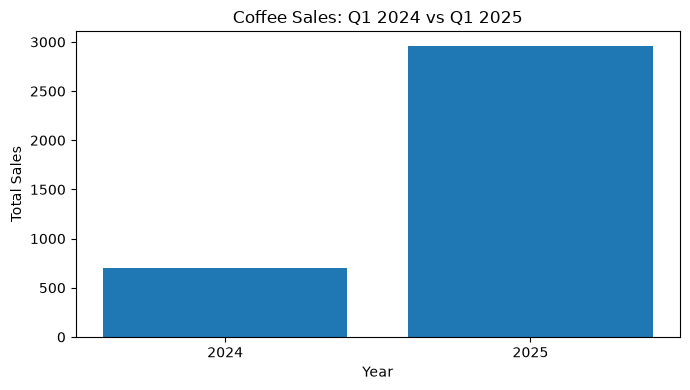

In [6]:
# Prepare date information
df["date"] = pd.to_datetime(df["date"])
df["year"] = df["date"].dt.year
df["quarter"] = df["date"].dt.quarter

# Select Q1 sales for 2024 and 2025
q1_sales = df[
    (df["quarter"] == 1) &
    (df["year"].isin([2024, 2025]))
]

# Calculate total sales
total_sales = q1_sales.groupby("year")["price"].sum()

# Generate chart
fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(total_sales.index.astype(str), total_sales.values)

ax.set_title("Coffee Sales: Q1 2024 vs Q1 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales")

plt.tight_layout()
plt.savefig("coffee_sales_initial.png", dpi=300)
plt.show()
plt.close(fig)

## 4. Reflection and Evaluation

The **Reflection Agent** uses an OpenAI vision-capable model to evaluate the initial chart and identify opportunities for improvement.

The evaluation considers four criteria:

1. **Clarity:** Is the chart easy to read and understand?
2. **Chart selection:** Is the visualisation appropriate for the data?
3. **Presentation:** Are titles, labels and formatting clear?
4. **Accuracy:** Could the chart mislead readers?

The model returns actionable feedback, which is passed to the code-generation model during the refinement stage.

This demonstrates the **Reflection design pattern**, where an LLM evaluates an earlier output and uses feedback to guide improvements.

**Limitation:** LLM-generated feedback may be inaccurate and should not automatically be treated as correct.

In [7]:
import base64

def reflect_on_chart(image_path: str) -> str:
    """Evaluate a chart using an OpenAI vision model."""

    # Encode the chart image
    with open(image_path, "rb") as image_file:
        image_base64 = base64.b64encode(
            image_file.read()
        ).decode("utf-8")

    prompt = """
    You are an expert in data visualisation.

    Evaluate this chart based on:
    1. Clarity and readability.
    2. Appropriate chart type.
    3. Titles, labels and formatting.
    4. Potentially misleading presentation.

    Provide three specific, actionable improvements.
    Keep your feedback concise.
    """

    response = client.responses.create(
        model="gpt-4o-mini",
        input=[
            {
                "role": "user",
                "content": [
                    {"type": "input_text", "text": prompt},
                    {
                        "type": "input_image",
                        "image_url": (
                            f"data:image/png;base64,{image_base64}"
                        ),
                    },
                ],
            }
        ],
    )

    return response.output_text.strip()

In [8]:
# Evaluate the initial chart
feedback = reflect_on_chart("coffee_sales_initial.png")

print("Reflection Agent Feedback:\n")
print(feedback)

Reflection Agent Feedback:

### Evaluation of the Chart

1. **Clarity and Readability**: The chart is clear, but the significant difference in sales between the two years may mislead viewers without context. The aspect ratio might emphasize the gap instead of providing a true comparison.

2. **Appropriate Chart Type**: A bar chart is suitable for comparing discrete values between two categories. However, a line or area chart might convey trends over time more effectively.

3. **Titles, Labels, and Formatting**: The title is descriptive, but the axes could benefit from clearer labels (e.g., "Total Sales" can specify the unit). The y-axis does not start at zero, which distorts the visual comparison.

4. **Potentially Misleading Presentation**: The large gap between values can exaggerate the perceived increase in sales. The y-axis scale can mislead viewers regarding the percentage growth.

### Actionable Improvements

1. **Adjust the Y-Axis**: Begin the y-axis at zero to provide a more ac

## 5. Chart Refinement

The refinement stage uses feedback from the Reflection Agent to generate improved Python code.

The OpenAI model receives:

- **Original instruction:** The initial chart requirements.
- **Reflection feedback:** Suggestions for improving the visualisation.
- **Dataset columns:** Information needed to generate compatible Python code.

The model then generates revised code incorporating the relevant improvements, such as adding data labels, improving formatting and ensuring the y-axis starts at zero.

This completes one cycle of the **Generate → Execute → Reflect → Refine** workflow.

**Note:** The revised code is inspected before a manually reviewed implementation produces the final chart. Code execution is not yet automated.

In [9]:
def refine_chart_code(instruction: str, feedback: str) -> str:
    """Generate improved chart code using reflection feedback."""

    prompt = f"""
    You are a Python data visualisation expert.

    Original task:
    {instruction}

    Reflection feedback:
    {feedback}

    Dataset columns:
    {list(df.columns)}

    Generate improved Python code using the existing DataFrame 'df'.

    Requirements:
    - Use Pandas and Matplotlib.
    - Keep a bar chart for comparing two quarters.
    - Start the y-axis at zero.
    - Add numerical labels above the bars.
    - Use clear titles and axis labels.
    - Save the chart as 'coffee_sales_refined.png'.
    - Close the figure after saving.
    - Return Python code only, without Markdown fences.
    """

    response = client.responses.create(
        model="gpt-4o-mini",
        input=prompt
    )

    return response.output_text.strip()

In [ ]:
# Generate refined chart code
refined_code = refine_chart_code(
    instruction,
    feedback
)

print(refined_code)

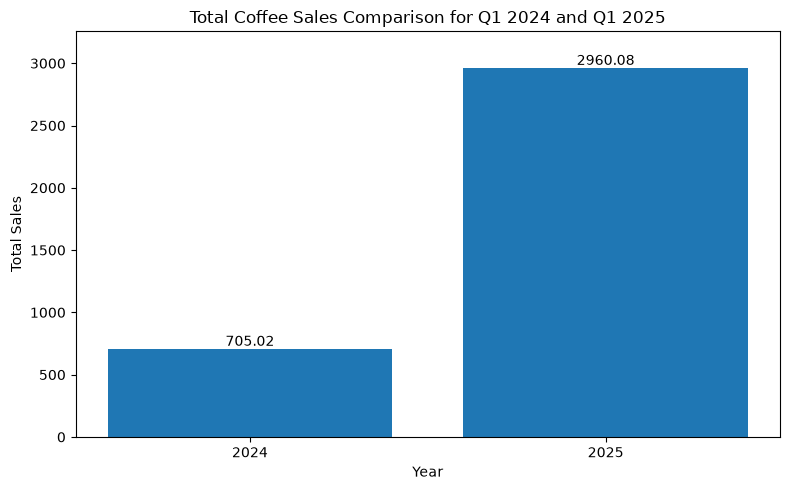

In [11]:
# Filter Q1 sales for 2024 and 2025
q1_sales = df[
    (df["quarter"] == 1) &
    (df["year"].isin([2024, 2025]))
]

# Summarise total sales
total_sales = q1_sales.groupby("year")["price"].sum()

# Create chart
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    total_sales.index.astype(str),
    total_sales.values
)

# Add value labels
for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        yval,
        f"{yval:.2f}",
        ha="center",
        va="bottom"
    )

# Format chart
ax.set_title("Total Coffee Sales Comparison for Q1 2024 and Q1 2025")
ax.set_xlabel("Year")
ax.set_ylabel("Total Sales")
ax.set_ylim(0, total_sales.max() * 1.1)

plt.tight_layout()
plt.savefig("coffee_sales_refined.png", dpi=300)
plt.show()
plt.close(fig)

## 6. Conclusion

This project demonstrates the **Reflection design pattern** in agentic AI through an iterative data visualisation workflow.

An OpenAI model generates Python code for a chart, a vision-capable model evaluates the resulting visualisation, and the feedback guides the generation of improved code.

### Key Concepts Demonstrated

- **LLM-based code generation:** Translating natural-language instructions into Python code.
- **Tool use:** Using Python, Pandas and Matplotlib to produce visualisations.
- **Reflection:** Evaluating chart quality using a vision-capable LLM.
- **Iterative refinement:** Improving outputs based on feedback.

### Limitations and Future Work

The current implementation requires manual review and execution of generated code. It also relies on subjective LLM feedback, which may occasionally be incorrect.

Future improvements could include isolated code execution, automated data validation, structured evaluation criteria and multiple refinement cycles.

This project was inspired by the *DeepLearning.AI Agentic AI* course and adapted as a practical exploration of agentic design patterns.